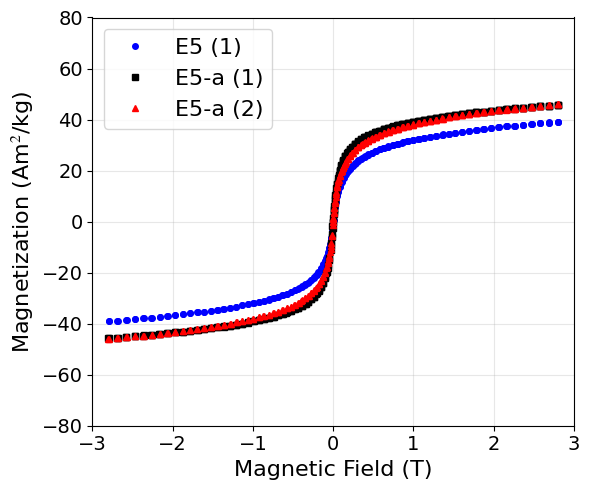

In [14]:
# Standalone experimental M-H plotting script
# Reads VersaLab-style CSV files 
# plots mass-normalized magnetization vs magnetic field as points 

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Inputs
MH_DIR = Path(
    r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Experimental_datasets"
)

OUT_DIR = MH_DIR

MH_FILES = [
    #r"E1_M-B.csv",
    #r"E2_M-B.csv",
    #r"E3_M-B.csv",
    #r"E3_measured_again_260414_M-B_300K_2.csv",
    #r"E3-aged_remade_M-B.csv",
    #r"E4_M-B.csv",
    #r"E4_measured_again_260520_M-B_300K_2.csv",
    #r"E4-aged_remade_M-B.csv",
    r"E5_M-B.csv",
    r"E5-aged_measured_again_260414_M-B_300K_3.csv",
    r"E5-aged_remade_M-B.csv",
]

# Masses in grams for each sample 1:1 correspondance with above files
MASSES_G = [  
    #0.0015,
    #0.0021,
    #0.0033,
    #0.0033,
    #0.007, # measured was 0.0068 to 0.007, used 0.007 range recorded in orignal csv file
    #0.0033,
    #0.0033,
    #0.0050,
    0.0011,
    0.0011,
    0.0253, 
]

# Labels for legend
LEGEND_LABELS = [
    #"E3 (1)",
    #"E3-a (1)",
    #"E3-a (2)",
    #"E4 (1)",
    #"E4-a (1)",
    #"E4-a (2)",
    "E5 (1)",
    "E5-a (1)",
    "E5-a (2)",
]

# Colors
COLORS_MH = ["b", "k", "r", "m", "darkorange"]

# Marker shapes for each sample
MARKERS_MH = ["o", "s", "^", "v", "P"]


# Marker sizes for each sample
MARKER_SIZES_MH = [4, 4, 4, 4, 4]

# VersaLab CSV format
# row 36 in Excel is zero-based row 35
# column D is index 3 = field (Oe)
# column E is index 4 = moment (emu)
MH_START_ROW = 35
MH_COL_FIELD = 3
MH_COL_MOM   = 4

# Plot style
FONTS = dict(ax=16, tick=14, legend=16, title=16)
FIGSIZE_MH = (6, 5)

# Axis limits; set to None to autoscale
X_LIMS = (-3, 3)
Y_LIMS = (-80, 80)

SAVE_FIG = False
SAVE_NAME = "experimental_MB_overlay_points.png"
DPI = 300

# Load experimental M-B data
def load_mh_csv_full(path, mass_g, start_row=MH_START_ROW,
                     col_field=MH_COL_FIELD, col_moment=MH_COL_MOM):
    """
    Read VersaLab-style CSV:
      - field in Oe from column D
      - magnetic moment in emu from column E
      - data starts at row 36 in Excel (zero-based row 35)

    Returns:
      B_T : magnetic field in Tesla
      M   : magnetization in Am^2/kg
    """
    df = pd.read_csv(path, header=None)

    sub = df.iloc[start_row:, [col_field, col_moment]].copy()
    sub.columns = ["H_Oe", "m_emu"]

    B_T = sub["H_Oe"].to_numpy(dtype=float) * 1e-4
    M = sub["m_emu"].to_numpy(dtype=float) / float(mass_g)

    mask = np.isfinite(B_T) & np.isfinite(M)
    return B_T[mask], M[mask]


def _label_from_list(lst, idx, fallback):
    try:
        s = lst[idx]
        return s if isinstance(s, str) and len(s) > 0 else fallback
    except Exception:
        return fallback


def plot_selected_mh():
    assert len(MH_FILES) == len(MASSES_G), "MH_FILES and MASSES_G must have the same length."
    OUT_DIR.mkdir(parents=True, exist_ok=True)

    plt.figure(figsize=FIGSIZE_MH)

    for i, (mh_name, mass_g) in enumerate(zip(MH_FILES, MASSES_G)):
        mh_path = MH_DIR / mh_name
        if not mh_path.exists():
            raise FileNotFoundError(f"Missing M-B file: {mh_path}")

        B_true, M_true = load_mh_csv_full(mh_path, mass_g)

        label = _label_from_list(LEGEND_LABELS, i, Path(mh_name).stem)
        color = COLORS_MH[i % len(COLORS_MH)]
        marker = MARKERS_MH[i % len(MARKERS_MH)]
        ms = MARKER_SIZES_MH[i % len(MARKER_SIZES_MH)]

        plt.plot(
            B_true, M_true,
            linestyle='none',
            marker=marker,
            ms=ms,
            color=color,
            label=label
        )

    plt.xlabel("Magnetic Field (T)", fontsize=FONTS["ax"])
    plt.ylabel("Magnetization (Am$^2$/kg)", fontsize=FONTS["ax"])

    if X_LIMS is not None:
        plt.xlim(*X_LIMS)
    if Y_LIMS is not None:
        plt.ylim(*Y_LIMS)

    plt.grid(alpha=0.3)
    plt.legend(fontsize=FONTS["legend"])
    plt.tick_params(labelsize=FONTS["tick"])
    plt.tight_layout()

    if SAVE_FIG:
        plt.savefig(OUT_DIR / SAVE_NAME, dpi=DPI, bbox_inches="tight")

    plt.show()


if __name__ == "__main__":
    plot_selected_mh()

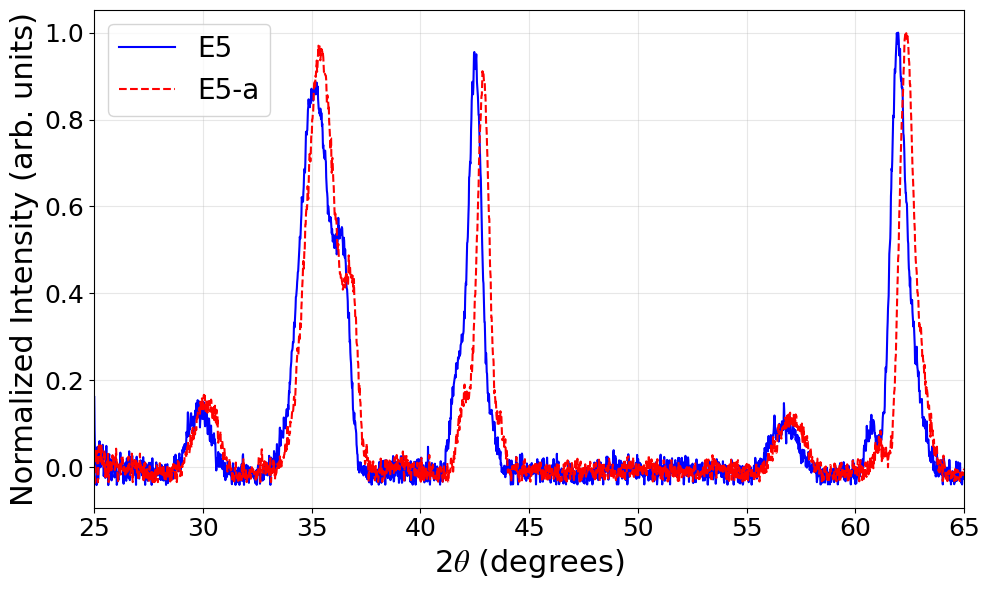

In [13]:
import os
import matplotlib as mpl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

mpl.rcParams["text.usetex"] = False
mpl.rcParams["font.family"] = "DejaVu Sans"
mpl.rcParams["mathtext.fontset"] = "stix" 

# Plots XRD data with cropping and max value normalization

# USER INPUTS

# File location
data_dir = r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Experimental_datasets"
 
file_list = [
    #"E1_XRD_20520.csv_bg_sub.csv",
    #"E2_XRD_20520_bg_sub.csv",
    #"E3_XRD_20520_bg_sub.csv",
    #"E3-aged_XRD_20520_bg_sub.csv",
    #"E4_XRD_20520_bg_sub.csv",
    #"E4-aged_XRD_20520_bg_sub.csv",
    "E5_XRD_20520_bg_sub.csv",
    "E5-aged_XRD_20520_bg_sub.csv",
]

# Labels for legend
plot_labels = [
    #"E3",
    #"E3-a",
    #"E4",
    #"E4-a",
    "E5",
    "E5-a",
]

# Colors
color_list = [
    "blue",
    "red",
]

# Line styles
linestyle_list = [
    "solid",
    "dashed",
]

x_col = "two_theta"
y_col = "intensity"

# Plot styling
x_label = r"2$\theta$ (degrees)"
y_label = "Normalized Intensity (arb. units)"
title = "XRD Comparison"

font_size_axes_labels = 22
font_size_ticks = 18
font_size_title = 16
legend_font = 20
line_width = 1.5

# x-limits
x_min = 25
x_max = 65

save_fig = False
output_filename = ".png"
output_dpi = 600

# LOAD, CROP, NORMALIZE, PLOT

fig, ax = plt.subplots(figsize=(10, 6))

for i, fname in enumerate(file_list):
    fpath = os.path.join(data_dir, fname)

    df = pd.read_csv(
        fpath,
        header=None,
        names=[x_col, y_col]
    )

    # extract x (2θ) and y (intensity)
    x = df[x_col].to_numpy()
    y = df[y_col].to_numpy()

    # crop first between x_min and x_max
    mask = (x >= x_min) & (x <= x_max)
    x_crop = x[mask]
    y_crop = y[mask]

    # max normalize cropped data
    y_max = np.max(y_crop)

    if y_max == 0:
        y_norm = np.zeros_like(y_crop)
    else:
        y_norm = y_crop / y_max

    ax.plot(
        x_crop,
        y_norm,
        linewidth=line_width,
        label=plot_labels[i],
        color=color_list[i],
        linestyle=linestyle_list[i],
    )

# axis labels and ticks
ax.set_xlabel(x_label, fontsize=font_size_axes_labels)
ax.set_ylabel(y_label, fontsize=font_size_axes_labels)
# ax.set_title(title, fontsize=font_size_title)

ax.tick_params(axis='both', which='both', labelsize=font_size_ticks)

# x-limits
ax.set_xlim([x_min, x_max])

# legend
ax.legend(fontsize=legend_font)

# transparent background
ax.set_facecolor("none")
fig.patch.set_alpha(0.0)

plt.tight_layout()
plt.grid(True, alpha=0.3)

# save figure
if save_fig:
    fig.savefig(
        output_filename,
        dpi=output_dpi,
        transparent=True
    )

plt.show()

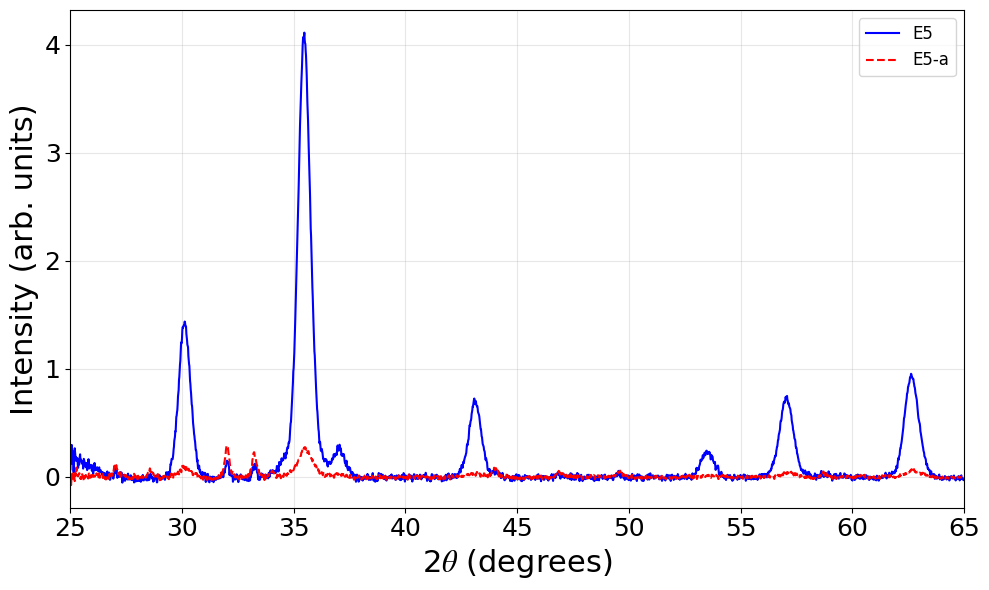

In [15]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# Plots XRD only crops the data

# Plot configuration
mpl.rcParams["text.usetex"] = False
mpl.rcParams["font.family"] = "DejaVu Sans"
mpl.rcParams["mathtext.fontset"] = "stix"


# User inputs
data_dir = Path(
    r"C:\Users\fabel\Documents\Abel_Lab"
    r"\Iron_Oxide_Model_Restructured\Experimental_datasets"
)

file_list = [
    "E3_XRD_20520_bg_sub.csv",
    "USNA_XRD_plate_20520_bg_sub.csv",
    #"E5_XRD_20520_bg_sub.csv",
    #"E5-aged_XRD_20520_bg_sub.csv",
]

plot_labels = [
    "E5",
    "E5-a",
]

color_list = [
    "blue",
    "red",
]

linestyle_list = [
    "solid",
    "dashed",
]

x_col = "two_theta"
y_col = "intensity"

x_label = r"2$\theta$ (degrees)"
y_label = "Intensity (arb. units)"

font_size_axes_labels = 22
font_size_ticks = 18
line_width = 1.5

# Inclusive cropping range
x_min = 25.0
x_max = 65.0

save_fig = False
output_path = data_dir / ".png"
output_dpi = 600

# Basic configuration validation
n_files = len(file_list)

if not (
    len(plot_labels)
    == len(color_list)
    == len(linestyle_list)
    == n_files
):
    raise ValueError(
        "file_list, plot_labels, color_list, and linestyle_list "
        "must have the same length."
    )

# Load, validate, crop, and plot
fig, ax = plt.subplots(figsize=(10, 6))

for fname, label, color, linestyle in zip(
    file_list,
    plot_labels,
    color_list,
    linestyle_list,
):
    file_path = data_dir / fname

    if not file_path.is_file():
        raise FileNotFoundError(f"XRD file not found: {file_path}")

    # Files were verified to contain two numeric columns with no header.
    df = pd.read_csv(
        file_path,
        header=None,
        dtype=np.float64,
        skip_blank_lines=False,
    )

    if df.shape[1] != 2:
        raise ValueError(
            f"{file_path.name} contains {df.shape[1]} columns; "
            "exactly two were expected."
        )

    df.columns = [x_col, y_col]

    if df.isna().any().any():
        raise ValueError(
            f"{file_path.name} contains missing or nonnumeric values."
        )

    x = df[x_col].to_numpy(copy=False)
    y = df[y_col].to_numpy(copy=False)

    if not np.all(np.isfinite(x)) or not np.all(np.isfinite(y)):
        raise ValueError(
            f"{file_path.name} contains non-finite values."
        )

    if not np.all(np.diff(x) > 0):
        raise ValueError(
            f"The two-theta values in {file_path.name} "
            "are not strictly increasing."
        )

    # The only data processing operation: crop by two-theta.
    crop_mask = (x >= x_min) & (x <= x_max)

    if not np.any(crop_mask):
        raise ValueError(
            f"{file_path.name} contains no data between "
            f"{x_min} and {x_max} degrees."
        )

    x_crop = x[crop_mask]
    y_crop = y[crop_mask]

    ax.plot(
        x_crop,
        y_crop,
        linewidth=line_width,
        label=label,
        color=color,
        linestyle=linestyle,
    )


# Ploting
ax.set_xlabel(x_label, fontsize=font_size_axes_labels)
ax.set_ylabel(y_label, fontsize=font_size_axes_labels)

ax.tick_params(
    axis="both",
    which="both",
    labelsize=font_size_ticks,
)

ax.set_xlim(x_min, x_max)
ax.legend(fontsize=12)
ax.grid(True, alpha=0.3)

ax.set_facecolor("none")
fig.patch.set_alpha(0.0)

fig.tight_layout()


# Save or display
if save_fig:
    fig.savefig(
        output_path,
        dpi=output_dpi,
        transparent=True,
    )
    print(f"Saved figure to:\n{output_path}")

plt.show()

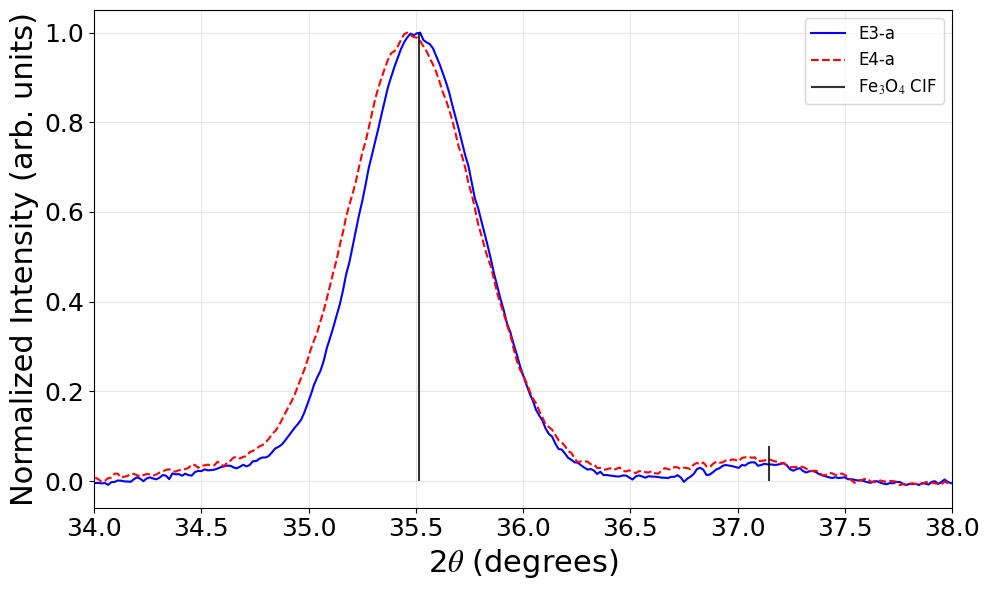

In [3]:
import os
import matplotlib as mpl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pymatgen.core import Structure
from pymatgen.analysis.diffraction.xrd import XRDCalculator

mpl.rcParams["text.usetex"] = False
mpl.rcParams["font.family"] = "DejaVu Sans"
mpl.rcParams["mathtext.fontset"] = "stix" 

# Plots XRD with stick CIF intensity

# File location
data_dir = r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Experimental_datasets"

# CIF location
cif_dir = r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\CIF"
cif_filename = "1010369_Fe3O4.cif"
cif_path = os.path.join(cif_dir, cif_filename)

file_list = [
    #"E1_XRD_20520_bg_sub.csv",
    #"E2_XRD_20520_bg_sub.csv",
    #"E3_XRD_20520_bg_sub.csv",
    "E3-aged_XRD_20520_bg_sub.csv",
    #"E4_XRD_20520_bg_sub.csv",
    "E4-aged_XRD_20520_bg_sub.csv",
    #"E4_XRD_20520_bg_sub_raw_2theta_shift_p0p193625deg.csv", # Bruker processed shift
]

# Labels for legend
plot_labels = [
    #"E1",
    #"E2",
    "E3-a",
    #"E4-a",
    #"E4",
    "E4-a",
    #"E4-shift"
]

# Colors
color_list = [
    #"blue",
    #"red",
    "blue", 
    #"darkorange",
    "red", 
]

# Line styles
linestyle_list = [
    "solid",
    "dashed",
    #"dotted",
]

# CIF stick-pattern style
stick_label = "Fe$_3$O$_4$ CIF"
stick_color = "black"
stick_linewidth = 1.5
stick_alpha = 0.8

x_col = "two_theta"
y_col = "intensity"

# Plot styling
x_label = r"2$\theta$ (degrees)"
y_label = "Normalized Intensity (arb. units)"
title = "XRD Comparison"

font_size_axes_labels = 22
font_size_ticks = 18
font_size_title = 16
line_width = 1.5

# x-limits
x_min = 34
x_max = 38

save_fig = False
output_filename = ".png"
output_dpi = 600

# LOAD, CROP, NORMALIZE, PLOT

fig, ax = plt.subplots(figsize=(10, 6))

for i, fname in enumerate(file_list):
    fpath = os.path.join(data_dir, fname)

    df = pd.read_csv(
        fpath,
        header=None,
        names=[x_col, y_col]
    )

    # extract x (2θ) and y (intensity)
    x = df[x_col].to_numpy()
    y = df[y_col].to_numpy()

    # crop first between x_min and x_max
    mask = (x >= x_min) & (x <= x_max)
    x_crop = x[mask]
    y_crop = y[mask]

    # max normalize cropped data
    y_max = np.max(y_crop)

    if y_max == 0:
        y_norm = np.zeros_like(y_crop)
    else:
        y_norm = y_crop / y_max

    ax.plot(
        x_crop,
        y_norm,
        linewidth=line_width,
        label=plot_labels[i],
        color=color_list[i],
        linestyle=linestyle_list[i],
    )

# LOAD CIF AND PLOT MAX-NORMALIZED STICK PATTERN

structure = Structure.from_file(cif_path)

calc = XRDCalculator(wavelength="CuKa")
pattern = calc.get_pattern(
    structure,
    scaled =False,
    two_theta_range=(x_min, x_max)
)

stick_x = np.asarray(pattern.x)
stick_y = np.asarray(pattern.y)

# max normalize CIF stick intensities
if stick_y.max() == 0:
    stick_y_norm = np.zeros_like(stick_y)
else:
    stick_y_norm = stick_y / stick_y.max()

ax.vlines(
    stick_x,
    ymin=0,
    ymax=stick_y_norm,
    colors=stick_color,
    linewidth=stick_linewidth,
    alpha=stick_alpha,
    label=stick_label
)

# axis labels and ticks
ax.set_xlabel(x_label, fontsize=font_size_axes_labels)
ax.set_ylabel(y_label, fontsize=font_size_axes_labels)
# ax.set_title(title, fontsize=font_size_title)

ax.tick_params(axis='both', which='both', labelsize=font_size_ticks)

# x-limits
ax.set_xlim([x_min, x_max])

# legend
ax.legend(fontsize=12)

# transparent background
ax.set_facecolor("none")
fig.patch.set_alpha(0.0)

plt.tight_layout()
plt.grid(True, alpha=0.3)

# save figure
if save_fig:
    fig.savefig(
        output_filename,
        dpi=output_dpi,
        transparent=True
    )

plt.show()

C:\Users\fabel\AppData\Local\Temp\ipykernel_6836\589798488.py:115: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=12)


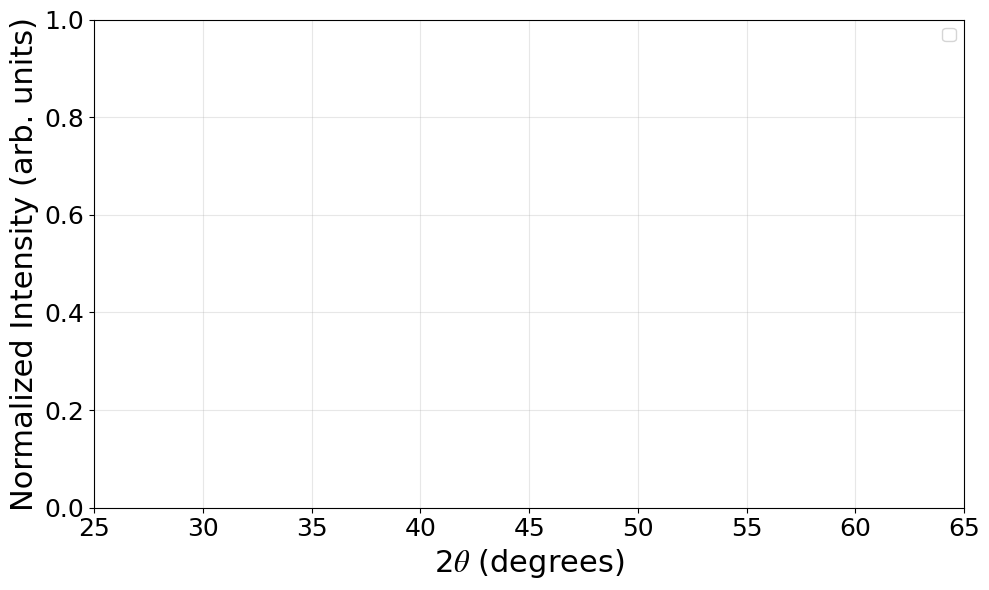

In [6]:
import os
import matplotlib as mpl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

mpl.rcParams["text.usetex"] = False
mpl.rcParams["font.family"] = "DejaVu Sans"
mpl.rcParams["mathtext.fontset"] = "stix" 


# min.-max normalized XRD plotting

# USER INPUTS

# File location
data_dir = r"C:\Users\fabel\Documents\Abel_Lab\Iron_Oxide_Model_Restructured\Experimental_datasets"
 
file_list = [

]

# Labels for legend
plot_labels = [
    #"20520 s",
    #"20520 s, aged",
    "E4",
    "E4, aged",
]

# Colors
color_list = [
    "blue",
    "red",
]

# Line styles
linestyle_list = [
    "solid",
    "dashed",
]

x_col = "two_theta"
y_col = "intensity"

# Plot styling
x_label = r"2$\theta$ (degrees)"
y_label = "Normalized Intensity (arb. units)"
title = "XRD Comparison"

font_size_axes_labels = 22
font_size_ticks = 18
font_size_title = 16
line_width = 1.5

# x-limits
x_min = 25
x_max = 65

save_fig = False
output_filename = "E.png"
output_dpi = 600

# LOAD, CROP, NORMALIZE, PLOT

fig, ax = plt.subplots(figsize=(10, 6))

for i, fname in enumerate(file_list):
    fpath = os.path.join(data_dir, fname)

    df = pd.read_csv(
        fpath,
        header=None,
        names=[x_col, y_col]
    )

    # extract x (2θ) and y (intensity)
    x = df[x_col].to_numpy()
    y = df[y_col].to_numpy()

    # crop first between x_min and x_max
    mask = (x >= x_min) & (x <= x_max)
    x_crop = x[mask]
    y_crop = y[mask]

    # min-max normalize cropped data
    y_min = np.min(y_crop)
    y_max = np.max(y_crop)

    if y_max - y_min == 0:
        y_norm = np.zeros_like(y_crop)
    else:
        y_norm = (y_crop - y_min) / (y_max - y_min)

    ax.plot(
        x_crop,
        y_norm,
        linewidth=line_width,
        label=plot_labels[i],
        color=color_list[i],
        linestyle=linestyle_list[i],
    )

# axis labels and ticks
ax.set_xlabel(x_label, fontsize=font_size_axes_labels)
ax.set_ylabel(y_label, fontsize=font_size_axes_labels)
# ax.set_title(title, fontsize=font_size_title)

ax.tick_params(axis='both', which='both', labelsize=font_size_ticks)

# x-limits
ax.set_xlim([x_min, x_max])

# legend
ax.legend(fontsize=12)

# transparent background
ax.set_facecolor("none")
fig.patch.set_alpha(0.0)

plt.tight_layout()
plt.grid(True, alpha=0.3)

# save figure
if save_fig:
    fig.savefig(
        output_filename,
        dpi=output_dpi,
        transparent=True
    )

plt.show()

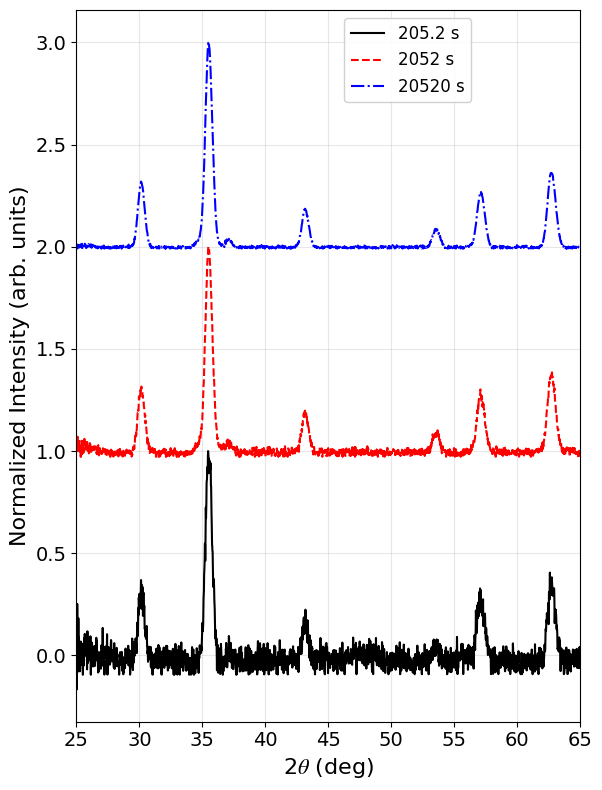

In [34]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# USER INPUTS

# File location
data_dir = (
    r"C:\Users\fabel\Documents\Abel_Lab"
    r"\Iron_Oxide_Model_Restructured\Experimental_datasets"
)

# List of file names
file_list = [
    #"E2_XRD_205_bg_sub.csv",
    #"E2_XRD_2052_bg_sub.csv",
    #"E2_XRD_20520_bg_sub.csv",
    "E3-aged_XRD_205_bg_sub.csv",
    "E3-aged_XRD_2052_bg_sub.csv",
    "E3-aged_XRD_20520_bg_sub.csv",
    #"E5-aged_XRD_205_bg_sub.csv",
    #"E5-aged_XRD_2052_bg_sub.csv",
    #"E5-aged_XRD_20520_bg_sub.csv",
]

# Labels
plot_labels = [
    "205.2 s",
    "2052 s",
    "20520 s",
]

color_list = [
    "black",
    "red",
    "blue",
]

linestyle_list = [
    "solid",    # first XRD pattern
    "dashed",   # second XRD pattern
    "dashdot",  # third XRD pattern
]

x_col = "two_theta"
y_col = "intensity"

# Plot styling
x_label = r"2$\theta$ (deg)"
y_label = "Normalized Intensity (arb. units)"
title = "XRD Comparison"

font_size_axes_labels = 16
font_size_ticks = 14
font_size_title = 16

line_width = 1.5

# Legend styling and position
legend_font_size = 12
legend_loc = "upper right"
legend_anchor = (0.8, 1)

#offset_step = 1.5  # used for E5-aged
#offset_step = 1.0    # used for E2
offset_step = 1.0 # used E3-aged

# Crop limits
x_min = 25
x_max = 65

save_fig = False
output_filename = "xrd_overlay.png"
output_dpi = 600


# LOAD, CROP, NORMALIZE, AND PLOT

fig, ax = plt.subplots(figsize=(6, 8))

for i, fname in enumerate(file_list):
    fpath = os.path.join(data_dir, fname)

    df = pd.read_csv(
        fpath,
        header=None,
        names=[x_col, y_col],
    )

    # Convert values to numeric. Malformed or textual values become NaN.
    x = pd.to_numeric(df[x_col], errors="coerce").to_numpy()
    y = pd.to_numeric(df[y_col], errors="coerce").to_numpy()

    # Remove rows containing invalid x or y values.
    valid = np.isfinite(x) & np.isfinite(y)
    x = x[valid]
    y = y[valid]

    # Crop the data before normalization.
    crop_mask = np.ones(x.shape, dtype=bool)

    if x_min is not None:
        crop_mask &= x >= x_min

    if x_max is not None:
        crop_mask &= x <= x_max

    x = x[crop_mask]
    y = y[crop_mask]

    if x.size == 0:
        raise ValueError(
            f"No data from '{fname}' falls within "
            f"the range {x_min} to {x_max} degrees."
        )

    # Normalize by the maximum intensity in the cropped range.
    y_max = np.max(y)

    if np.isclose(y_max, 0.0):
        y_norm = np.zeros_like(y, dtype=float)
    else:
        y_norm = y / y_max

    # Apply vertical offset.
    y_offset = y_norm + i * offset_step

    # Choose legend label.
    if i < len(plot_labels):
        label_i = plot_labels[i]
    else:
        label_i = fname

    # Choose color.
    if i < len(color_list):
        color_i = color_list[i]
    else:
        color_i = None

    # Choose linestyle.
    if i < len(linestyle_list):
        linestyle_i = linestyle_list[i]
    else:
        linestyle_i = "solid"

    ax.plot(
        x,
        y_offset,
        linewidth=line_width,
        label=label_i,
        color=color_i,
        linestyle=linestyle_i,
    )


# AXIS LABELS, TITLE, AND TICKS

ax.set_xlabel(x_label, fontsize=font_size_axes_labels)
ax.set_ylabel(y_label, fontsize=font_size_axes_labels)
# ax.set_title(title, fontsize=font_size_title)

ax.tick_params(
    axis="both",
    which="both",
    labelsize=font_size_ticks,
)

# Display the same cropped range.
if x_min is not None or x_max is not None:
    ax.set_xlim(left=x_min, right=x_max)

# Legend

# Legend styling and position
ax.legend(
    fontsize=legend_font_size,
    loc=legend_loc,
    bbox_to_anchor=legend_anchor,
    framealpha=0.9,
)

# Transparent axes and figure background.
ax.set_facecolor("none")
fig.patch.set_alpha(0.0)

ax.grid(True, alpha=0.3)
plt.tight_layout()

# plt.ylim(0, 2.1)

# Save transparent figure.
if save_fig:
    fig.savefig(
        output_filename,
        dpi=output_dpi,
        transparent=True,
    )

plt.show()